# 03 - Modelos de regresión

Probamos tres modelos de las clases (regresión lineal, kNN, árbol de decisión) para predecir
`corr_futura_60d`. Los hiperparámetros se eligen con **validación temporal** dentro de train y recién
al final se mira test.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent          # el notebook corre desde notebooks/
sys.path.append(str(RAIZ / "backend"))  # para importar app.dataset y app.modelo
DATA = RAIZ / "data"

plt.rcParams["figure.figsize"] = (8, 4)

In [2]:
from sklearn.tree import export_text

from app.modelo import (FEATURES, TARGET, ajustar, candidatos, dividir_temporal,
                        metricas, predecir_baseline, splits_temporales)

dataset = pd.read_csv(DATA / "dataset_pares.csv", parse_dates=["fecha_corte"])
train, test = dividir_temporal(dataset)
print(len(train), "filas de train |", len(test), "filas de test")

32625 filas de train | 14355 filas de test


## 1. Validación temporal (en vez de validación cruzada común)

Para elegir hiperparámetros necesitamos datos de validación que no sean test. La validación cruzada
común mezclaría fechas, así que usamos **ventana expansiva**: cada fold entrena con el pasado y valida
con el bloque siguiente (con gap).

In [3]:
folds = splits_temporales(train["fecha_corte"].unique(), n_splits=4)
for k, (f_tr, f_va) in enumerate(folds, 1):
    print(f"fold {k}: train {pd.Timestamp(f_tr[0]).date()} a {pd.Timestamp(f_tr[-1]).date()} | "
          f"val {pd.Timestamp(f_va[0]).date()} a {pd.Timestamp(f_va[-1]).date()}")

fold 1: train 2014-12-30 a 2015-11-12 | val 2016-03-10 a 2017-04-20
fold 2: train 2014-12-30 a 2017-01-24 | val 2017-05-18 a 2018-06-28
fold 3: train 2014-12-30 a 2018-04-04 | val 2018-07-27 a 2019-09-09
fold 4: train 2014-12-30 a 2019-06-13 | val 2019-10-07 a 2020-11-13


## 2. Modelos y grilla de hiperparámetros

In [4]:
for nombre, c in candidatos().items():
    print(nombre, "->", c["grilla"] or "(sin hiperparámetros)")

regresion_lineal -> (sin hiperparámetros)
knn -> {'kneighborsregressor__n_neighbors': [15, 50, 150, 400, 1000]}
arbol -> {'max_depth': [2, 3, 5, 8], 'min_samples_leaf': [5, 20, 100, 400]}


- **Regresión lineal:** estandariza las features y ajusta un hiperplano. Es el más simple e interpretable.
- **kNN:** predice el promedio del target de los `k` pares más parecidos del pasado.
- **Árbol:** parte el espacio con reglas `feature <= valor`; `max_depth` y `min_samples_leaf` controlan el overfitting.

`ajustar` prueba cada combinación de la grilla en los folds, se queda con la de menor MAE de validación
y reentrena con todo train.

In [5]:
modelos, info = {}, {}
for nombre in candidatos():
    modelos[nombre], params, mae_val = ajustar(nombre, train)
    info[nombre] = {"parametros": params, "mae_validacion": round(mae_val, 4)}
pd.DataFrame(info).T

,parametros,mae_validacion
regresion_lineal,{},0.2067
knn,{'kneighborsregressor__n_neighbors': 1000},0.201
arbol,"{'max_depth': 5, 'min_samples_leaf': 5}",0.2185


## 3. Resultado en test contra el baseline

In [6]:
predicciones = {"baseline": predecir_baseline(test)}
predicciones.update({n: m.predict(test[FEATURES]) for n, m in modelos.items()})

tabla = pd.DataFrame({n: metricas(test[TARGET], p) for n, p in predicciones.items()}).T
tabla["mejora_mae_vs_baseline_%"] = (1 - tabla["mae"] / tabla.loc["baseline", "mae"]) * 100
tabla.round(4)

,mae,rmse,r2,mejora_mae_vs_baseline_%
baseline,0.1612,0.2042,0.2109,0.0000
regresion_lineal,0.1564,0.1931,0.2945,3.0082
knn,0.1613,0.1986,0.2538,-0.0827
arbol,0.2011,0.2480,-0.1639,-24.7449


El modelo se **elige por MAE de validación**, no por test (mirar test para elegir sería usarlo para
entrenar). Después se informa su resultado en test, sea bueno o malo.

In [7]:
elegido = min(info, key=lambda n: info[n]["mae_validacion"])
print("elegido por validación:", elegido)

elegido por validación: knn


## 4. Qué aprendió cada modelo

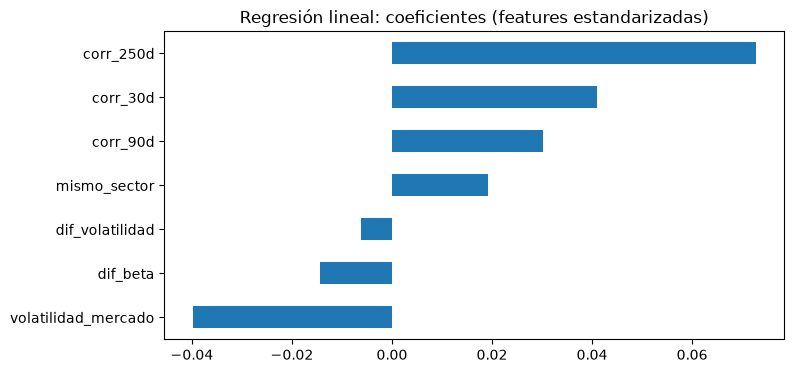

In [8]:
# Coeficientes de la regresión lineal (features estandarizadas => comparables entre sí)
lineal = modelos["regresion_lineal"]
coef = pd.Series(lineal[-1].coef_, index=FEATURES).sort_values()
coef.plot.barh(title="Regresión lineal: coeficientes (features estandarizadas)")
plt.show()

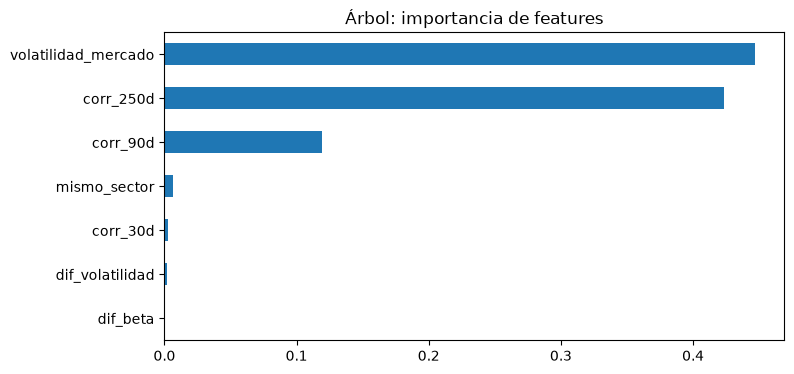

|--- corr_250d <= 0.33
|   |--- corr_250d <= 0.17
|   |   |--- volatilidad_mercado <= 0.00
|   |   |   |--- corr_250d <= -0.03
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- corr_250d >  -0.03
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- volatilidad_mercado >  0.00
|   |   |   |--- volatilidad_mercado <= 0.01
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- volatilidad_mercado >  0.01
|   |   |   |   |--- truncated branch of depth 2
|   |--- corr_250d >  0.17
|   |   |--- volatilidad_mercado <= 0.01
|   |   |   |--- volatilidad_mercado <= 0.01
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- volatilidad_mercado >  0.01
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- volatilidad_mercado >  0.01
|   |   |   |--- volatilidad_mercado <= 0.01
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- volatilidad_mercado >  0.01
|   |   |   |   |--- truncated branch of depth 2
|--- corr_250d >  0.33
| 

In [9]:
# Importancia de features y reglas del árbol
arbol = modelos["arbol"]
pd.Series(arbol.feature_importances_, index=FEATURES).sort_values().plot.barh(title="Árbol: importancia de features")
plt.show()
print(export_text(arbol, feature_names=FEATURES, max_depth=3))

## Lectura de resultados

- **La mejora sobre el baseline es chica.** La regresión lineal baja el MAE ~3% y sube el R² de 0.21 a 0.29.
  Hay señal, pero la correlación futura es difícil de predecir: gran parte es ruido de mercado.
- **El modelo elegido por validación (kNN) empata con el baseline en test** (MAE casi idéntico). La lineal, que
  salió segunda en validación, es la que mejor anda en test. Elegir por validación es lo correcto (si no se usaría
  test para decidir), pero hay que reportar este resultado tal cual.
- **kNN eligió `k = 1000`, el extremo de la grilla.** Un `k` tan grande promedia casi todo: el modelo se comporta
  como una función muy suave y deja de distinguir pares parecidos. Conviene probar `k` más grande o admitir que más
  flexibilidad no ayuda con estas features.
- **El árbol es el peor** en test (MAE 0.20, R² negativo: peor que predecir la media). Probable causa: sobreajuste a
  features ruidosas; para confirmarlo habría que comparar su error en train contra el de test.

## Cosas para pensar

1. ¿Por qué `corr_90d` y `corr_250d` pesan tanto? ¿Qué agregan `mismo_sector` o `volatilidad_mercado`?
2. ¿Alcanza una mejora de ~3% para justificar el ML, o el aporte real del TP está en el grafo?
3. ¿Qué cambiaría si eligiéramos por test en vez de validación? (Pista: elegiría otro modelo, y sería trampa.)